# Module 04: RAG, Embeddings & Vector Databases
**Codomax Digital Solutions · GenAI Internship · Day 16 – Day 20**
**Intern:** Vishva Yadav · B.E. Computer Engineering

| # | Key objective | Section |
|---|---|---|
| 1 | LLM hallucinations and the idea of Retrieval-Augmented Generation (RAG) | Part 1 |
| 2 | Embeddings, semantic similarity, document processing, chunking, vector databases | Parts 2–4 |
| 3 | Connect retrieved context to an LLM, document Q&A, improve retrieval quality | Parts 5–6 |
| 4 | "Chat With Your Documents" app: Document → Chunking → Embeddings → Vector DB → Retrieval → LLM → Answer | `app.py` in this repo |

**Stack (all free):** Google Gemini API (chat + embeddings, free tier) · ChromaDB (open-source vector database) · NumPy

## 0 · Setup
1. Free API key: **aistudio.google.com → API Keys** (Free tier, no card).
2. Colab 🔑 **Secrets** → `GEMINI_API_KEY` → enable *Notebook access*.
3. **Runtime → Run all.** 💸 Cost: ₹0.

In [1]:
!pip install -q google-genai chromadb pandas matplotlib tabulate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.


In [2]:
import os, re, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google import genai
from google.genai import types

try:
    from google.colab import userdata
    API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    API_KEY = os.environ.get("GEMINI_API_KEY")
if not API_KEY:
    raise RuntimeError("GEMINI_API_KEY not found. Add it in Colab → 🔑 Secrets.")

# 60 s timeout, no hidden SDK retries (we retry ourselves)
client = genai.Client(api_key=API_KEY, http_options=types.HttpOptions(
    timeout=60_000, retry_options=types.HttpRetryOptions(attempts=1)))

def version(n):
    m = re.search(r"(\d+(?:\.\d+)?)", n); return float(m.group(1)) if m else 0.0

models = list(client.models.list())
def with_action(action):
    return [m.name.removeprefix("models/") for m in models if action in (m.supported_actions or [])]

skip = ("image", "tts", "audio", "live", "embedding", "robotics", "computer-use", "veo", "imagen")
chat_candidates = sorted([n for n in with_action("generateContent") if n.startswith("gemini") and not any(s in n for s in skip)],
                         key=lambda n: (0 if "flash" in n and "lite" not in n else 1 if "flash-lite" in n else 2,
                                        "preview" in n or "exp" in n, -version(n)))
embed_candidates = sorted(with_action("embedContent"), key=lambda n: ("gemini" not in n, "exp" in n, -version(n)))
print("Chat models available:", chat_candidates[:6])
print("Embedding models available:", embed_candidates[:4])

def retry(fn, tries=4):
    for i in range(tries):
        try:
            return fn()
        except Exception as e:
            code = getattr(e, "code", None)
            if i == tries - 1 or not (code == 429 or (code or 0) >= 500):
                raise
            print(f"  ({code}) retrying in {10 * (i + 1)}s...")
            time.sleep(10 * (i + 1))

# Pick the first chat model that actually answers
CHAT_MODEL = None
for m in chat_candidates:
    try:
        retry(lambda: client.models.generate_content(model=m, contents="hi"), tries=2)
        CHAT_MODEL = m; break
    except Exception as e:
        print(f"{m} not usable: {str(e)[:80]}")
EMBED_MODEL = embed_candidates[0]
print("\n✅ Chat model:", CHAT_MODEL, "| ✅ Embedding model:", EMBED_MODEL)

def ask(prompt, system=None, temperature=0.2):
    cfg = types.GenerateContentConfig(temperature=temperature, system_instruction=system)
    return retry(lambda: client.models.generate_content(model=CHAT_MODEL, contents=prompt, config=cfg)).text or ""

EMBED_ONE_BY_ONE = False   # newer embedding models merge a list into ONE vector; then we embed one text at a time

def _embed_call(contents, task_type):
    try:
        return retry(lambda: client.models.embed_content(model=EMBED_MODEL, contents=contents,
                                                         config=types.EmbedContentConfig(task_type=task_type)))
    except Exception as e:
        if getattr(e, "code", None) != 400:
            raise
        return retry(lambda: client.models.embed_content(model=EMBED_MODEL, contents=contents))  # no task_type support

def embed(texts, task_type="RETRIEVAL_DOCUMENT"):
    """Return an (n, dim) array: one embedding per text."""
    global EMBED_ONE_BY_ONE
    out = []
    for i in range(0, len(texts), 100):
        batch = texts[i:i + 100]
        if not EMBED_ONE_BY_ONE:
            r = _embed_call(batch, task_type)
            if len(r.embeddings) == len(batch):
                out += [e.values for e in r.embeddings]
                continue
            EMBED_ONE_BY_ONE = True
            print("ℹ️ This embedding model returns one vector per request, so texts are embedded one at a time.")
        for t in batch:
            out.append(_embed_call(t, task_type).embeddings[0].values)
            time.sleep(0.7)   # stay under the free-tier requests-per-minute limit
    return np.array(out, dtype=np.float32)

def show(title, text):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}\n{text}")

Chat models available: ['gemini-3.8-flash', 'gemini-3.7-flash', 'gemini-3.6-flash', 'gemini-3.5-flash', 'gemini-2.5-flash', 'gemini-omni-1.2-flash']
Embedding models available: ['gemini-embedding-2-preview', 'gemini-embedding-2', 'gemini-embedding-001']

✅ Chat model: gemini-3.8-flash | ✅ Embedding model: gemini-embedding-2-preview


In [3]:
HANDBOOK = '# Nimbus Labs Employee Handbook (Fictional Sample Document)\n\n> This is a made-up company handbook created to demonstrate Retrieval-Augmented Generation (RAG).\n> None of these policies belong to a real organization. Because the content is fictional, a language\n> model cannot know it from training data. It can only answer correctly by retrieving it.\n\n## 1. About Nimbus Labs\n\nNimbus Labs is a fictional robotics software company founded in 2019 by Meera Iyer and Daniel Okafor.\nThe headquarters is in Pune, India, with a smaller engineering office in Lisbon, Portugal.\nThe company builds navigation software for warehouse robots. Its flagship product is called\n**PathPilot**, and the second product, **DockSense**, helps robots find charging stations automatically.\nNimbus Labs has 140 employees as of 2026.\n\n## 2. Working Hours and Remote Work\n\nCore collaboration hours are 11:00 to 16:00 IST, Monday to Friday. Outside core hours, employees may\nplan their own schedule. Nimbus Labs follows a hybrid model: employees work from the office on\n**Tuesdays and Thursdays**, and may work remotely on the other weekdays. Fully remote work requires\nwritten approval from a department head and is reviewed every six months.\n\n## 3. Leave Policy\n\nEvery full-time employee receives **24 days of paid annual leave** per calendar year. Up to 8 unused\ndays can be carried forward to the next year; any additional unused days expire on 31 March.\nEmployees also receive 10 days of paid sick leave. Sick leave longer than 3 consecutive days requires\na medical certificate. Parental leave is 26 weeks for the primary caregiver and 6 weeks for the\nsecondary caregiver. Leave requests are submitted in the internal HR portal called **Nest** at least\ntwo weeks in advance, except for sick leave.\n\n## 4. Probation and Performance Reviews\n\nNew employees have a **probation period of 6 months**. During probation, the notice period is 15 days;\nafter confirmation it becomes 60 days. Performance reviews happen twice a year, in **April and October**.\nEach review uses a 5-point scale, and ratings of 4 or 5 make an employee eligible for the annual\nperformance bonus, which is paid in June.\n\n## 5. Learning and Development\n\nEach employee has a **learning budget of ₹40,000 per year** for courses, certifications, books and\nconference tickets. Unused budget does not carry over. Employees can also take 5 paid "learning days"\nper year to study or attend workshops. Requests above ₹15,000 for a single item need manager approval.\nEvery Friday from 16:00 to 17:00, the company hosts an internal knowledge-sharing session called\n**Cloud Talks**.\n\n## 6. Equipment and IT\n\nNew employees receive a laptop on their first day. Engineers may choose between a 14-inch MacBook Pro\nand a Linux laptop with 32 GB RAM. Laptops are replaced every **3 years**, or earlier if they fail.\nEmployees receive a one-time home-office allowance of ₹25,000 to buy a chair, monitor or desk.\nIT support is available through the **#it-help** Slack channel from 09:00 to 19:00 IST.\n\n## 7. Information Security\n\nMulti-factor authentication (MFA) is mandatory for all company accounts. Passwords must be at least\n14 characters long and stored only in the company password manager, **Vaultwarden**.\nAny suspected security incident, such as a lost laptop or a phishing email that was clicked,\nmust be reported to **security@nimbuslabs.example** within **2 hours** of discovery.\nCustomer robot data must never be copied to personal devices or uploaded to public AI tools.\n\n## 8. Travel and Expenses\n\nBusiness travel must be booked through the travel desk at least 7 days in advance when possible.\nEconomy class is standard for flights under 6 hours; premium economy is allowed for longer flights.\nThe daily meal allowance during business travel is **₹2,500 in India** and **€60 abroad**.\nExpense claims must be submitted with receipts within **30 days** of the expense date, using the\nNest portal. Claims submitted after 30 days need approval from the finance team.\n\n## 9. On-Call and Support\n\nEngineers on the PathPilot team join an on-call rotation of one week at a time, roughly once every\nsix weeks. On-call engineers receive an allowance of ₹6,000 per on-call week. The target response time\nfor critical incidents (severity 1) is **15 minutes**, and for severity 2 incidents it is 2 hours.\n\n## 10. Code of Conduct\n\nNimbus Labs expects respectful, inclusive behaviour from everyone. Harassment of any kind is not\ntolerated. Concerns can be raised with a manager, with HR, or anonymously through the **Ethics Line**.\nRetaliation against anyone who raises a concern in good faith is strictly prohibited.\n'

print(HANDBOOK[:600], '...')
print(f'\n{len(HANDBOOK):,} characters')

# Nimbus Labs Employee Handbook (Fictional Sample Document)

> This is a made-up company handbook created to demonstrate Retrieval-Augmented Generation (RAG).
> None of these policies belong to a real organization. Because the content is fictional, a language
> model cannot know it from training data. It can only answer correctly by retrieving it.

## 1. About Nimbus Labs

Nimbus Labs is a fictional robotics software company founded in 2019 by Meera Iyer and Daniel Okafor.
The headquarters is in Pune, India, with a smaller engineering office in Lisbon, Portugal.
The company builds navigation s ...

4,645 characters


## Part 1 · Hallucinations, and why we need RAG
An LLM only knows its **training data**. Ask it about private or new information, such as your company's policies, a PDF you just
wrote, or yesterday's news, and it will either **make something up confidently (hallucination)** or say it doesn't know.

Our test document is a handbook for **Nimbus Labs, a fictional company**, so the model *cannot* know these answers.

In [4]:
questions = [
    "What is the daily meal allowance abroad for Nimbus Labs employees?",
    "Within how many hours must Nimbus Labs employees report a security incident?",
    "What does the Nimbus Labs product DockSense do?",
]
for q in questions:
    show("❌ WITHOUT documents: " + q, ask(q))


❌ WITHOUT documents: What is the daily meal allowance abroad for Nimbus Labs employees?
Internal travel policies and meal allowances for **Nimbus Labs** employees are not publicly available information. 

To find the exact daily per diem or meal allowance rate for international travel, you should check your company's internal resources:

1. **Travel & Expense (T&E) Policy:** Usually available on your internal wiki/intranet (e.g., Notion, Confluence, or SharePoint).
2. **Expense Management Portal:** Check the guidelines or automated per diem rates in platforms like Concur, Expensify, or Navan/TripActions.
3. **Internal Contacts:** Reach out directly to your **Finance**, **Travel**, or **People Operations / HR** department for the current rates applicable to your specific destination.
  (503) retrying in 10s...

❌ WITHOUT documents: Within how many hours must Nimbus Labs employees report a security incident?
Specific incident reporting timeframes depend on the internal policies outlined

In [5]:
for q in questions:
    prompt = f"Answer using only this document:\n\n{HANDBOOK}\n\nQuestion: {q}"
    show("✅ WITH the document: " + q, ask(prompt))


✅ WITH the document: What is the daily meal allowance abroad for Nimbus Labs employees?
Based on the provided document, the daily meal allowance during business travel abroad is **€60**.

✅ WITH the document: Within how many hours must Nimbus Labs employees report a security incident?
Based on the document, Nimbus Labs employees must report any suspected security incident within **2 hours** of discovery (to security@nimbuslabs.example).

✅ WITH the document: What does the Nimbus Labs product DockSense do?
Based on the provided document, **DockSense** helps robots find charging stations automatically.


**Observation:** without the document the model guesses (hallucinates) or refuses. With the document, it answers correctly.

So why not always paste the whole document into the prompt? Real knowledge bases are **too big**: thousands of pages won't fit in the
context window, and sending everything every time is **slow and expensive**.

**RAG = Retrieval-Augmented Generation:**
1. Split documents into small **chunks**.
2. Convert each chunk into an **embedding** (a vector of numbers that captures meaning) and store it in a **vector database**.
3. For each question, **retrieve** only the most relevant chunks.
4. Give those chunks to the LLM as **context**, and ask it to answer *only from them*, **citing sources**.

## Part 2 · Embeddings & semantic similarity
An **embedding** turns text into a long list of numbers (a vector). Texts with similar *meaning* get vectors that point in similar
directions, even if they share no words. We measure this with **cosine similarity** (1.0 = same direction, about 0 = unrelated).

ℹ️ This embedding model returns one vector per request, so texts are embedded one at a time.
Each sentence becomes a vector of 3072 numbers. First 8 of sentence 1: [-0.001  0.009  0.006 -0.006  0.003 -0.013 -0.023  0.038]


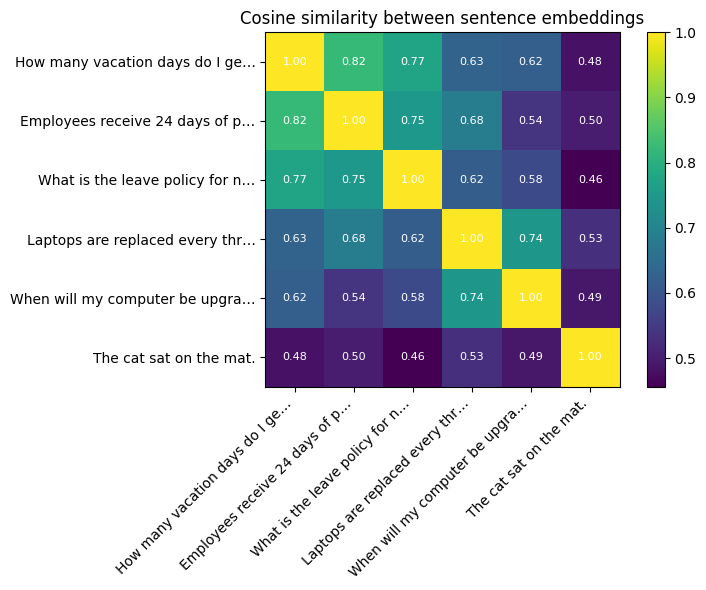

In [6]:
sentences = [
    "How many vacation days do I get?",
    "Employees receive 24 days of paid annual leave.",
    "What is the leave policy for new joiners?",
    "Laptops are replaced every three years.",
    "When will my computer be upgraded?",
    "The cat sat on the mat.",
]
E = embed(sentences, "SEMANTIC_SIMILARITY")
print("Each sentence becomes a vector of", E.shape[1], "numbers. First 8 of sentence 1:", np.round(E[0][:8], 3))

En = E / np.linalg.norm(E, axis=1, keepdims=True)
sim = En @ En.T

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(sim, cmap="viridis", vmin=sim.min(), vmax=1)
labels = [s[:30] + "…" if len(s) > 30 else s for s in sentences]
ax.set_xticks(range(len(sentences)), labels, rotation=45, ha="right"); ax.set_yticks(range(len(sentences)), labels)
for i in range(len(sentences)):
    for j in range(len(sentences)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("Cosine similarity between sentence embeddings"); plt.colorbar(im); plt.tight_layout(); plt.show()

**Observation:** "vacation days" and "paid annual leave" score high even though they share no keywords. "Laptops are replaced"
matches "computer be upgraded". The cat sentence is far from everything. That is **semantic** similarity.

In [7]:
# Keyword search vs semantic search
query = "How much time off can I take?"
paragraphs = [p.strip() for p in HANDBOOK.split("\n\n") if len(p.strip()) > 80]

keyword_hits = [p for p in paragraphs if any(w in p.lower() for w in ["time off"])]
print(f"🔤 Keyword search for 'time off': {len(keyword_hits)} matches")

P = embed(paragraphs); q = embed([query], "RETRIEVAL_QUERY")[0]
scores = (P / np.linalg.norm(P, axis=1, keepdims=True)) @ (q / np.linalg.norm(q))
best = int(np.argmax(scores))
show(f"🧠 Semantic search best match (similarity {scores[best]:.3f})", paragraphs[best])

🔤 Keyword search for 'time off': 0 matches

🧠 Semantic search best match (similarity 0.744)
Every full-time employee receives **24 days of paid annual leave** per calendar year. Up to 8 unused
days can be carried forward to the next year; any additional unused days expire on 31 March.
Employees also receive 10 days of paid sick leave. Sick leave longer than 3 consecutive days requires
a medical certificate. Parental leave is 26 weeks for the primary caregiver and 6 weeks for the
secondary caregiver. Leave requests are submitted in the internal HR portal called **Nest** at least
two weeks in advance, except for sick leave.


## Part 3 · Document processing & chunking
Before embedding, documents are **loaded** (PDF → text), **cleaned**, and **split into chunks**.

| Chunk size | Pros | Cons |
|---|---|---|
| Small (≈200–400 chars) | precise matches | may cut facts in half and lose context |
| Large (≈1500+ chars) | more context | less precise, more tokens per question |

**Overlap** repeats the end of a chunk at the start of the next one, so a fact on the boundary isn't lost.
Below we compare a **naive fixed-size splitter** with our **sentence- and heading-aware chunker** (the same code as `rag.py` in the app).

In [8]:
def naive_chunks(text, size=300, overlap=0):
    step = size - overlap
    return [text[i:i + size] for i in range(0, len(text), step)]

naive = naive_chunks(HANDBOOK, 300)
print("Naive fixed-size chunks often cut sentences and numbers in half:\n")
for c in naive[5:8]:
    print("…" + c[-90:].replace("\n", " ") + "|  ← chunk ends here\n")

Naive fixed-size chunks often cut sentences and numbers in half:

…d **Nest** at least two weeks in advance, except for sick leave.  ## 4. Probation and Perf|  ← chunk ends here

… and October**. Each review uses a 5-point scale, and ratings of 4 or 5 make an employee e|  ← chunk ends here

…ckets. Unused budget does not carry over. Employees can also take 5 paid "learning days" p|  ← chunk ends here



In [9]:
def _units(text: str) -> list[str]:
    """Split into paragraphs, then sentences: natural boundaries keep meaning together."""
    units = []
    for para in re.split(r"\n\s*\n", text):
        para = para.strip()
        if para:
            parts = [s.strip() for s in re.split(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(*#])", para) if s.strip()]
            merged: list[str] = []
            for s in parts:                        # keep "## 3." together with its heading text
                if merged and re.fullmatch(r"[#>*\s]*\d+(\.\d+)*\.", merged[-1]):
                    merged[-1] += " " + s
                else:
                    merged.append(s)
            units.extend(merged)
            units[-1] = units[-1] + "\n"           # remember the paragraph break
    return units


def chunk_text(text: str, chunk_size: int = 800, overlap: int = 150) -> list[str]:
    """Sentence-aware chunking: pack sentences into chunks of ≤ chunk_size characters.
    Each new chunk starts with the last ~overlap characters of the previous one, so facts
    that sit on a boundary are not lost."""
    overlap = max(0, min(overlap, chunk_size // 2))   # keep overlap smaller than a chunk
    pieces: list[str] = []
    for u in _units(text):                         # hard-split very long sentences
        while len(u) > chunk_size:
            pieces.append(u[:chunk_size])
            u = u[chunk_size - overlap:]
        pieces.append(u)

    chunks, current = [], []
    for p in pieces:
        size_now = sum(len(x) + 1 for x in current)
        if current and p.lstrip().startswith("#") and size_now > chunk_size * 0.25:
            chunks.append(" ".join(current).strip())  # structure-aware: a heading starts a new chunk
            current = []
        elif current and size_now + len(p) > chunk_size:
            chunks.append(" ".join(current).strip())
            tail, size = [], 0                     # carry the overlap forward
            for x in reversed(current):
                if size + len(x) > overlap:
                    break
                tail.insert(0, x)
                size += len(x) + 1
            current = tail
        current.append(p)
    if current:
        chunks.append(" ".join(current).strip())
    return [c for c in chunks if len(c) > 20]


smart = chunk_text(HANDBOOK, 500, 100)
print(f"Sentence/heading-aware chunks: {len(smart)}\n")
for c in smart[3:6]:
    print("▶", c[:200].replace("\n", " "), "...\n")

stats = []
for size, ov in [(300, 0), (300, 60), (800, 150), (1500, 200)]:
    cs = chunk_text(HANDBOOK, size, ov)
    stats.append({"chunk_size": size, "overlap": ov, "chunks": len(cs),
                  "avg_chars": int(np.mean([len(c) for c in cs]))})
pd.DataFrame(stats)

Sentence/heading-aware chunks: 12

▶ ## 3. Leave Policy  Every full-time employee receives **24 days of paid annual leave** per calendar year. Up to 8 unused days can be carried forward to the next year; any additional unused days expire ...

▶ Parental leave is 26 weeks for the primary caregiver and 6 weeks for the secondary caregiver. Leave requests are submitted in the internal HR portal called **Nest** at least two weeks in advance, exce ...

▶ ## 4. Probation and Performance Reviews  New employees have a **probation period of 6 months**. During probation, the notice period is 15 days; after confirmation it becomes 60 days. Performance revie ...



,chunk_size,overlap,chunks,avg_chars
0,300,0,22,209
1,300,60,24,199
2,800,150,11,420
3,1500,200,9,514


## Part 4 · Vector database (ChromaDB)
A **vector database** stores embeddings with their text and metadata and finds the nearest vectors to a query quickly.
We use **ChromaDB** (free, open-source, runs inside Colab) and give it our Gemini embeddings.

In [10]:
import chromadb

chroma = chromadb.Client()   # in-memory. chromadb.PersistentClient(path="db") would save to disk
try:
    chroma.delete_collection("handbook")
except Exception:
    pass
collection = chroma.create_collection("handbook", metadata={"hnsw:space": "cosine"})

def section_of(chunk):
    m = re.search(r"##\s*\d+\.\s*([^\n]+)", chunk)
    return m.group(1).strip() if m else "Intro"

chunks = chunk_text(HANDBOOK, 500, 100)
current = "Intro"; sections = []
for c in chunks:                       # carry the last seen heading forward as metadata
    s = section_of(c); current = s if s != "Intro" else current; sections.append(current)

collection.add(
    ids=[f"chunk-{i}" for i in range(len(chunks))],
    documents=chunks,
    embeddings=embed(chunks).tolist(),
    metadatas=[{"section": s, "chars": len(c)} for s, c in zip(sections, chunks)],
)
print("Stored", collection.count(), "chunks in ChromaDB")

def search(question, k=3, where=None):
    res = collection.query(query_embeddings=embed([question], "RETRIEVAL_QUERY").tolist(),
                           n_results=k, where=where)
    return [{"id": i, "section": m["section"], "similarity": round(1 - d, 3), "text": t}
            for i, m, d, t in zip(res["ids"][0], res["metadatas"][0], res["distances"][0], res["documents"][0])]

pd.DataFrame(search("How long do I have to submit my travel receipts?"))[["id", "section", "similarity", "text"]]

Stored 12 chunks in ChromaDB


,id,section,similarity,text
0,chunk-9,Travel and Expenses,0.765,## 8. Travel and Expenses\n Business travel mu...
1,chunk-3,Leave Policy,0.643,## 3. Leave Policy\n Every full-time employee ...
2,chunk-0,Intro,0.631,# Nimbus Labs Employee Handbook (Fictional Sam...


In [11]:
# Metadata filtering: search only inside one section
pd.DataFrame(search("What is the allowance?", k=2, where={"section": "On-Call and Support"}))[["section", "similarity", "text"]]

,section,similarity,text
0,On-Call and Support,0.648,## 9. On-Call and Support\n Engineers on the P...


## Part 5 · RAG: connect retrieved context to the LLM
`question → embed → retrieve top-k chunks → build a grounded prompt with numbered sources → LLM → answer with citations`

In [12]:
RAG_SYSTEM = """You answer questions about the user's documents.
Rules:
1. Use ONLY the CONTEXT. Do not use outside knowledge.
2. If the answer is not in the context, reply exactly: "I couldn't find this in the uploaded documents."
3. Cite sources like [1] or [2][3] after each fact.
4. Be concise."""

def rag_answer(question, k=3, verbose=True):
    hits = search(question, k=k)
    context = "\n\n".join(f"[{i}] (section: {h['section']})\n{h['text']}" for i, h in enumerate(hits, 1))
    answer = ask(f"CONTEXT:\n{context}\n\nQUESTION: {question}\n\nANSWER:", system=RAG_SYSTEM)
    if verbose:
        show("❓ " + question, answer)
        print("   sources:", [(h["section"], h["similarity"]) for h in hits])
    return answer, hits

for q in ["What is the daily meal allowance abroad?",
          "Within how many hours must a security incident be reported, and to whom?",
          "What does DockSense do?",
          "What is Nimbus Labs' stock price?"]:          # not in the document
    rag_answer(q)


❓ What is the daily meal allowance abroad?
The daily meal allowance abroad is €60 [1].
   sources: [('Travel and Expenses', 0.756), ('Leave Policy', 0.629), ('Equipment and IT', 0.618)]

❓ Within how many hours must a security incident be reported, and to whom?
A security incident must be reported within 2 hours of discovery to **security@nimbuslabs.example** [1].
   sources: [('Information Security', 0.757), ('On-Call and Support', 0.657), ('Code of Conduct', 0.653)]

❓ What does DockSense do?
DockSense helps robots find charging stations automatically [1].
   sources: [('About Nimbus Labs', 0.657), ('Intro', 0.589), ('Leave Policy', 0.556)]
  (504) retrying in 10s...
  (429) retrying in 20s...
  (504) retrying in 30s...


ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\nPlease retry in 4h32.664307455s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://aistudio.google.com/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Generate content requests per day limit exceeded on Free Tier. See https://aistudio.goog

**Observation:** answers now match the document and cite their sources. For the stock-price question, which is not in the
document, the model says it couldn't find it **instead of hallucinating**.

## Part 6 · Improving retrieval quality (with measurements)
If retrieval fails, the LLM can't answer, so we **measure retrieval** on a small labelled test set.

- **Hit rate@k:** % of questions where a chunk containing the answer is in the top-k results
- **MRR (Mean Reciprocal Rank):** rewards putting the right chunk first (1st = 1.0, 2nd = 0.5, 3rd = 0.33 …)

We compare chunk sizes and top-k values, then measure final **answer accuracy**.

In [ ]:
EVAL = [
    ("How many days of paid annual leave do employees get?", "24 days"),
    ("Which days do employees have to come to the office?", "Tuesdays and Thursdays"),
    ("How much money can I spend on courses each year?", "40,000"),
    ("How often are laptops replaced?", "3 years"),
    ("I lost my work laptop. Who do I tell?", "security@nimbuslabs.example"),
    ("What is the meal allowance per day when travelling outside India?", "€60"),
    ("How long is probation for new employees?", "6 months"),
    ("How fast must on-call engineers respond to a severity 1 incident?", "15 minutes"),
]
norm = lambda s: s.replace("**", "").lower()
Q = embed([q for q, _ in EVAL], "RETRIEVAL_QUERY")
Qn = Q / np.linalg.norm(Q, axis=1, keepdims=True)

rows = []
for size, ov in [(300, 50), (800, 150), (1500, 200)]:
    cs = chunk_text(HANDBOOK, size, ov)
    C = embed(cs); Cn = C / np.linalg.norm(C, axis=1, keepdims=True)
    S = Qn @ Cn.T
    for k in (1, 3):
        hits, rr = 0, 0.0
        for qi, (_, ans) in enumerate(EVAL):
            ranked = np.argsort(-S[qi])
            ranks = [r for r, ci in enumerate(ranked, 1) if norm(ans) in norm(cs[ci])]
            first = ranks[0] if ranks else None
            hits += bool(first and first <= k)
            rr += (1 / first) if first and first <= k else 0
        rows.append({"chunk_size": size, "overlap": ov, "chunks": len(cs), "top_k": k,
                     "hit_rate": hits / len(EVAL), "MRR": round(rr / len(EVAL), 3)})
    time.sleep(2)

results = pd.DataFrame(rows)
results

In [ ]:
pivot = results.pivot(index="chunk_size", columns="top_k", values="hit_rate")
ax = pivot.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel("hit rate"); ax.set_title("Retrieval hit rate by chunk size and top-k")
ax.legend(title="top-k"); plt.tight_layout(); plt.show()

In [ ]:
# End-to-end answer accuracy with the ChromaDB pipeline (chunk 500 / overlap 100, top-3)
answer_rows = []
for q, expected in EVAL:
    ans, hits = rag_answer(q, k=3, verbose=False)
    answer_rows.append({"question": q, "expected": expected, "answer": ans.strip()[:120],
                        "correct": norm(expected) in norm(ans)})
    time.sleep(2)
ans_df = pd.DataFrame(answer_rows)
print(f"Answer accuracy: {ans_df.correct.mean():.0%}")
ans_df

In [ ]:
# ---- Save an evaluation report (commit reports/rag_evaluation_report.md to GitHub)
os.makedirs("reports", exist_ok=True)
best = results.sort_values(["hit_rate", "MRR"], ascending=False).iloc[0]
report = "\n".join([
    "# RAG Evaluation Report: Nimbus Labs Handbook (fictional)",
    f"*Chat model:* `{CHAT_MODEL}` · *Embedding model:* `{EMBED_MODEL}` · *Questions:* {len(EVAL)} · "
    f"*Generated:* {time.strftime('%Y-%m-%d %H:%M')}",
    "", "## Retrieval quality", results.to_markdown(index=False), "",
    f"**Best retrieval setting:** chunk size {int(best.chunk_size)}, top-k {int(best.top_k)} "
    f"(hit rate {best.hit_rate:.0%}, MRR {best.MRR})", "",
    "## End-to-end answers (chunk 500, top-3)", f"**Answer accuracy: {ans_df.correct.mean():.0%}**", "",
    ans_df.to_markdown(index=False), "",
    "## Takeaways",
    "- Without retrieval the model cannot answer questions about private documents and may hallucinate.",
    "- Retrieving more chunks (top-3 vs top-1) raises the hit rate, because the right chunk is not always ranked first.",
    "- Chunk size is a trade-off: small chunks are precise but can split facts; large chunks need fewer hits but add noise and tokens.",
    "- A strict grounded prompt (\"use only the context\", \"cite sources\", \"say if not found\") prevents made-up answers.",
])
open("reports/rag_evaluation_report.md", "w").write(report)
print(report[:1200], "...\n\n✅ Saved reports/rag_evaluation_report.md")
try:
    from google.colab import files; files.download("reports/rag_evaluation_report.md")
except Exception:
    pass

## Key learnings
1. **Hallucinations:** LLMs fill knowledge gaps with plausible-sounding guesses. RAG grounds answers in real documents.
2. **Embeddings** capture *meaning*, so semantic search finds "paid annual leave" for "vacation days".
3. **Chunking matters:** respect sentences and headings, add overlap, and tune the size. Bad chunks mean bad retrieval.
4. **Vector databases** (ChromaDB, FAISS, Pinecone …) store embeddings and support fast similarity search plus metadata filters.
5. **Measure retrieval** (hit rate, MRR) before blaming the LLM. Retrieving top-k > 1 is an easy win.
6. **Grounded prompts with citations** let users verify answers, and "I couldn't find this" is better than a confident wrong answer.

➡️ The **Chat With Your Documents** app (`app.py`) puts all of this into a web UI: upload a PDF and ask questions with sources.